# Task 1: Generate Confusion Matrix - EfficientNet-B3

## Mục tiêu
- Load test set (532 images, 17 species) từ `G:\task-B-group-split\test\`
- Load model checkpoint EfficientNet-B3 (97.37% accuracy)
- Inference và tạo confusion matrix 17×17
- Highlight Cupressaceae intra-family errors
- Save outputs: PNG (300 DPI), PDF, error analysis

## Requirements
- Dataset đã được filter xuống 17 loài (chạy `00_data_preparation.ipynb` trước)
- Model checkpoint: `../models/efficientnet_b3_seed123_best.pth`

---
## Cell 1: Setup & Imports

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

# Root detection
ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(ROOT))

print(f"ROOT: {ROOT}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: D:\do_an\woodbench
PyTorch: 2.1.0+cpu
CUDA available: False


---
## Cell 2: Configuration

In [2]:
# Paths
DATA_DIR = Path(r"G:\task-B-group-split")  # Dataset location
MODEL_PATH = Path.cwd().parent / "models" / "efficientnet_b3_seed123_best.pth"
OUTPUT_DIR = Path.cwd().parent / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Model config
IMG_SIZE = 224
BATCH_SIZE = 32
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# 17 species - SORTED BY FAMILY (Cupressaceae first for intra-family analysis)
SPECIES_17 = [
    # Cupressaceae (8 species) - MUST be grouped together for intra-family analysis
    "Callitris columellaris",
    "Calocedrus rupestris",
    "Chamaecyparis obtusa",
    "Cryptomeria japonica",
    "Cunninghamia lanceolata",
    "Fokienia hodginsii",
    "Thujopsis dolabrata",
    "Xanthocyparis vietnamensis",
    # Pinaceae (7 species)
    "Araucaria araucana",
    "Picea glauca",
    "Pinus cernua",
    "Pinus dalatensis",
    "Pinus krempfii",
    "Pinus radiata",
    "Pseudotsuga brevifolia",
    # Podocarpaceae (1 species)
    "Podocarpus pilgeri",
    # Taxaceae (1 species)
    "Taxus wallichiana",
]

# Family mapping (for highlighting Cupressaceae)
FAMILY_MAPPING = {
    "Callitris columellaris": "Cupressaceae",
    "Calocedrus rupestris": "Cupressaceae",
    "Chamaecyparis obtusa": "Cupressaceae",
    "Cryptomeria japonica": "Cupressaceae",
    "Cunninghamia lanceolata": "Cupressaceae",
    "Fokienia hodginsii": "Cupressaceae",
    "Thujopsis dolabrata": "Cupressaceae",
    "Xanthocyparis vietnamensis": "Cupressaceae",
    "Araucaria araucana": "Pinaceae",
    "Picea glauca": "Pinaceae",
    "Pinus cernua": "Pinaceae",
    "Pinus dalatensis": "Pinaceae",
    "Pinus krempfii": "Pinaceae",
    "Pinus radiata": "Pinaceae",
    "Pseudotsuga brevifolia": "Pinaceae",
    "Podocarpus pilgeri": "Podocarpaceae",
    "Taxus wallichiana": "Taxaceae",
}

print(f"Dataset: {DATA_DIR}")
print(f"Model: {MODEL_PATH}")
print(f"Output: {OUTPUT_DIR}")
print(f"Device: {DEVICE}")
print(f"Species: {len(SPECIES_17)}")

Dataset: G:\task-B-group-split
Model: D:\do_an\woodbench\3 task\task1\models\efficientnet_b3_seed123_best.pth
Output: D:\do_an\woodbench\3 task\task1\outputs
Device: cpu
Species: 17


---
## Cell 3: Dataset Class

In [6]:
class WoodTestDataset(Dataset):
    """Dataset for test split"""
    
    def __init__(self, data_dir, split='test'):
        self.data_dir = data_dir
        self.split_dir = data_dir / split
        
        # Get species list
        self.species_list = sorted([d.name for d in self.split_dir.iterdir() if d.is_dir()])
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.species_list)}
        
        # Transform
        self.transform = T.Compose([
            T.Resize((IMG_SIZE, IMG_SIZE)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
        
        # Index images
        self.image_paths = []
        self.labels = []
        
        for species in tqdm(self.species_list, desc=f"Loading {split}"):
            species_dir = self.split_dir / species
            species_files = sorted(list(species_dir.glob("*.png")) + list(species_dir.glob("*.jpg")))
            
            label = self.class_to_idx[species]
            for img_path in species_files:
                self.image_paths.append(img_path)
                self.labels.append(label)
            
            print(f"    {species}: {len(species_files)} images")
        
        print(f"[✓] Total: {len(self.image_paths)} images from {len(self.species_list)} species")
    
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        
        return img, label

---
## Cell 4: Load Dataset

In [7]:
print("[1/3] Loading test dataset...")
print("-" * 70)

dataset = WoodTestDataset(DATA_DIR, split='test')
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"\n[✓] Dataset ready: {len(dataset)} images, {len(dataloader)} batches")

[1/3] Loading test dataset...
----------------------------------------------------------------------


Loading test: 100%|██████████| 17/17 [00:00<00:00, 2016.49it/s]

    Araucaria araucana: 30 images
    Callitris columellaris: 34 images
    Calocedrus rupestris: 24 images
    Chamaecyparis obtusa: 33 images
    Cryptomeria japonica: 33 images
    Cunninghamia lanceolata: 27 images
    Fokienia hodginsii: 39 images
    Picea glauca: 25 images
    Pinus cernua: 31 images
    Pinus dalatensis: 32 images
    Pinus krempfii: 36 images
    Pinus radiata: 31 images
    Podocarpus pilgeri: 36 images
    Pseudotsuga brevifolia: 29 images
    Taxus wallichiana: 26 images
    Thujopsis dolabrata: 34 images
    Xanthocyparis vietnamensis: 32 images
[✓] Total: 532 images from 17 species

[✓] Dataset ready: 532 images, 17 batches


---
## Cell 5: Load Model

In [8]:
print("[2/3] Loading model...")
print("-" * 70)

# Create model
model = timm.create_model('efficientnet_b3', pretrained=False, num_classes=len(SPECIES_17))

# Load checkpoint
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE)

# Handle different checkpoint formats
if 'model_state_dict' in checkpoint:
    model.load_state_dict(checkpoint['model_state_dict'])
elif 'state_dict' in checkpoint:
    model.load_state_dict(checkpoint['state_dict'])
else:
    model.load_state_dict(checkpoint)

model = model.to(DEVICE)
model.eval()

print(f"[✓] Model loaded: EfficientNet-B3 ({len(SPECIES_17)} classes)")
print(f"[✓] Device: {DEVICE}")

[2/3] Loading model...
----------------------------------------------------------------------
[✓] Model loaded: EfficientNet-B3 (17 classes)
[✓] Device: cpu


---
## Cell 6: Inference

In [9]:
print("[3/3] Running inference...")
print("-" * 70)

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(dataloader, desc="Inference"):
        images = images.to(DEVICE)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print(f"[✓] Inference completed: {len(all_preds)} predictions")

# Accuracy
accuracy = 100 * (all_preds == all_labels).sum() / len(all_labels)
print(f"[✓] Accuracy: {accuracy:.2f}% ({(all_preds == all_labels).sum()}/{len(all_labels)})")

[3/3] Running inference...
----------------------------------------------------------------------


Inference: 100%|██████████| 17/17 [01:00<00:00,  3.53s/it]

[✓] Inference completed: 532 predictions
[✓] Accuracy: 93.42% (497/532)


---
## Cell 7: Compute Confusion Matrix

In [10]:
# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Save raw
np.save(OUTPUT_DIR / 'confusion_matrix_raw.npy', cm)
print(f"[✓] Raw confusion matrix saved: {OUTPUT_DIR / 'confusion_matrix_raw.npy'}")

print(f"\nConfusion matrix shape: {cm.shape}")
print(f"Diagonal sum (correct): {cm.diagonal().sum()}")
print(f"Total samples: {cm.sum()}")

[✓] Raw confusion matrix saved: D:\do_an\woodbench\3 task\task1\outputs\confusion_matrix_raw.npy

Confusion matrix shape: (17, 17)
Diagonal sum (correct): 497
Total samples: 532


---
## Cell 8: Plot Confusion Matrix

[✓] Confusion matrix saved:
    - D:\do_an\woodbench\3 task\task1\outputs\confusion_matrix_efficientnet_b3.png
    - D:\do_an\woodbench\3 task\task1\outputs\confusion_matrix_efficientnet_b3.pdf


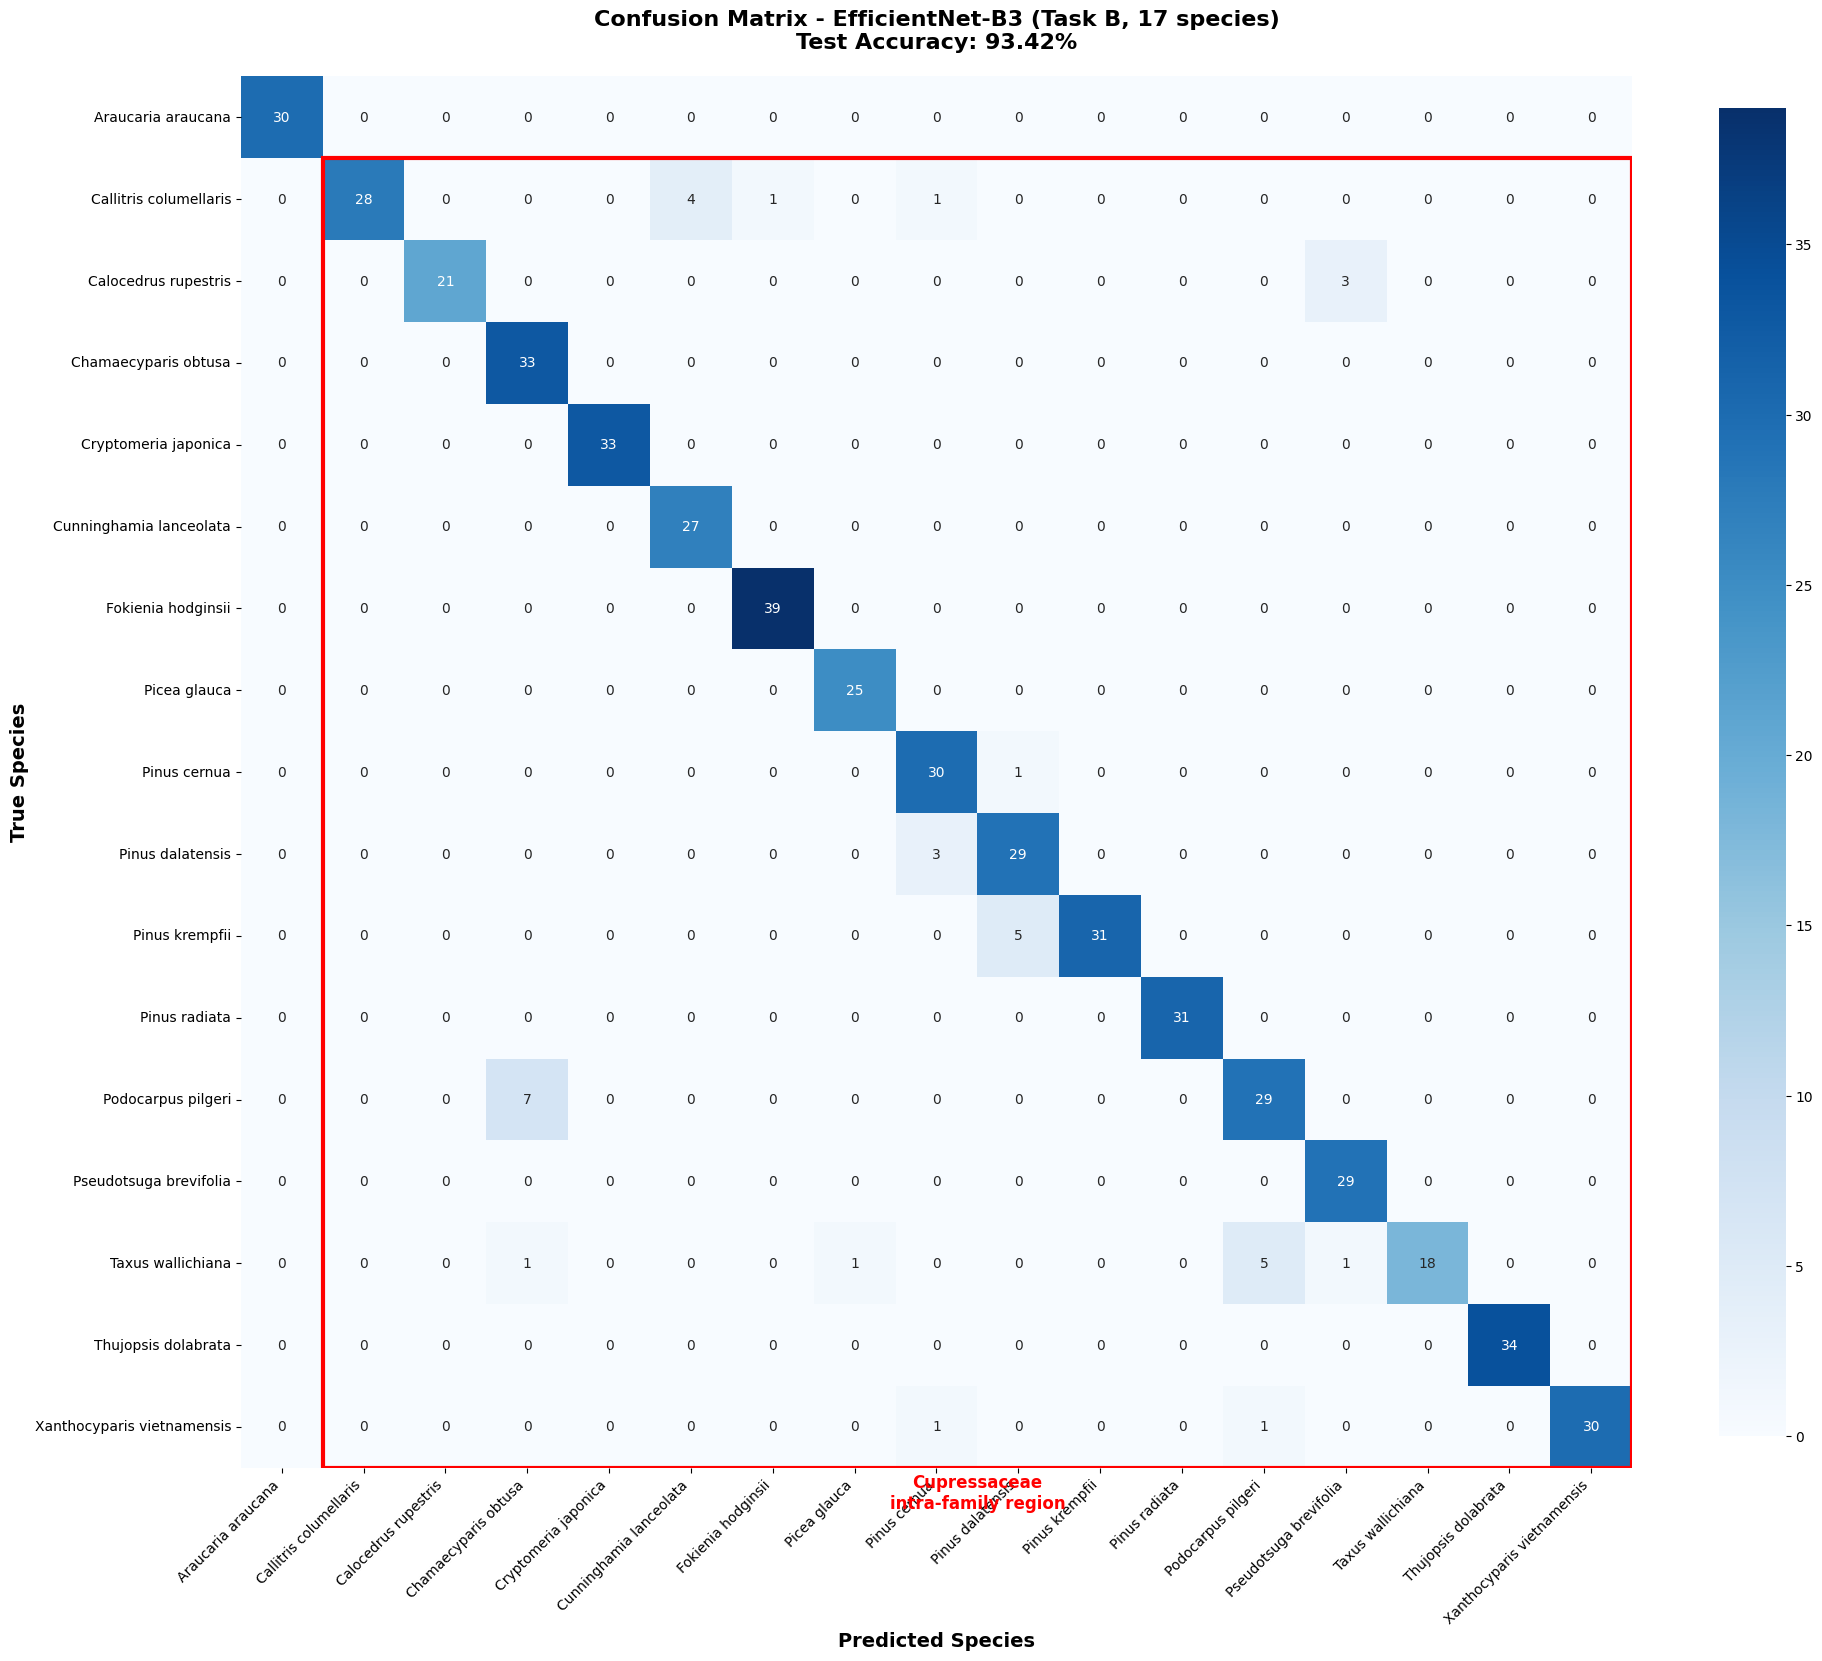

In [11]:
fig, ax = plt.subplots(figsize=(20, 18))

# Plot heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=SPECIES_17, yticklabels=SPECIES_17,
            square=True, ax=ax, cbar_kws={'shrink': 0.8})

# Identify Cupressaceae indices
cupressaceae_indices = [
    i for i, name in enumerate(SPECIES_17)
    if FAMILY_MAPPING.get(name) == "Cupressaceae"
]

# Highlight Cupressaceae region
if len(cupressaceae_indices) > 0:
    min_idx = min(cupressaceae_indices)
    max_idx = max(cupressaceae_indices) + 1
    
    from matplotlib.patches import Rectangle
    rect = Rectangle(
        (min_idx, min_idx), 
        max_idx - min_idx, 
        max_idx - min_idx,
        fill=False, 
        edgecolor='red', 
        linewidth=3
    )
    ax.add_patch(rect)
    
    ax.text(
        min_idx + (max_idx - min_idx) / 2, 
        max_idx + 0.5,
        'Cupressaceae\nintra-family region',
        ha='center',
        fontsize=12,
        color='red',
        fontweight='bold'
    )

# Labels
ax.set_xlabel('Predicted Species', fontsize=14, fontweight='bold')
ax.set_ylabel('True Species', fontsize=14, fontweight='bold')
ax.set_title(
    f'Confusion Matrix - EfficientNet-B3 (Task B, 17 species)\nTest Accuracy: {accuracy:.2f}%',
    fontsize=16, fontweight='bold', pad=20
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()

# Save
plt.savefig(OUTPUT_DIR / 'confusion_matrix_efficientnet_b3.png', dpi=300, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / 'confusion_matrix_efficientnet_b3.pdf', bbox_inches='tight')

print(f"[✓] Confusion matrix saved:")
print(f"    - {OUTPUT_DIR / 'confusion_matrix_efficientnet_b3.png'}")
print(f"    - {OUTPUT_DIR / 'confusion_matrix_efficientnet_b3.pdf'}")

plt.show()

---
## Cell 9: Error Analysis

In [12]:
report = []
report.append("=" * 70)
report.append("INTRA-FAMILY ERROR ANALYSIS")
report.append("=" * 70)

# Overall
total_samples = cm.sum()
correct = cm.diagonal().sum()
accuracy_val = 100 * correct / total_samples

report.append(f"\nOverall Accuracy: {accuracy_val:.2f}% ({int(correct)}/{int(total_samples)})")
report.append(f"Total Errors: {int(total_samples - correct)}")

# Cupressaceae errors
if len(cupressaceae_indices) > 0:
    report.append("\n" + "-" * 70)
    report.append("CUPRESSACEAE INTRA-FAMILY ERRORS")
    report.append("-" * 70)
    
    cupressaceae_errors = []
    for i in cupressaceae_indices:
        for j in cupressaceae_indices:
            if i != j and cm[i, j] > 0:
                cupressaceae_errors.append((
                    SPECIES_17[i], 
                    SPECIES_17[j], 
                    int(cm[i, j])
                ))
    
    if cupressaceae_errors:
        cupressaceae_errors.sort(key=lambda x: x[2], reverse=True)
        report.append(f"\nTotal intra-family errors: {sum(e[2] for e in cupressaceae_errors)}")
        report.append("\nTop confused pairs:")
        for true_sp, pred_sp, count in cupressaceae_errors[:5]:
            report.append(f"  {true_sp:<40s} → {pred_sp:<40s}: {count:>3d}")
    else:
        report.append("\nNo intra-family errors found!")

# Per-class
report.append("\n" + "-" * 70)
report.append("PER-CLASS PERFORMANCE")
report.append("-" * 70)
report.append(f"\n{'Species':<45s} {'Family':<15s} {'Correct':>7s} {'Total':>7s} {'Acc%':>6s}")
report.append("-" * 90)

for i, name in enumerate(SPECIES_17):
    correct_i = cm[i, i]
    total_i = cm[i, :].sum()
    acc_i = 100 * correct_i / total_i if total_i > 0 else 0
    family = FAMILY_MAPPING.get(name, "Unknown")
    
    report.append(f"{name:<45s} {family:<15s} {int(correct_i):>7d} {int(total_i):>7d} {acc_i:>6.1f}")

# Save
report_text = "\n".join(report)
(OUTPUT_DIR / 'error_analysis.txt').write_text(report_text, encoding='utf-8')

print(f"[✓] Error analysis saved: {OUTPUT_DIR / 'error_analysis.txt'}")
print("\n" + report_text)

[✓] Error analysis saved: D:\do_an\woodbench\3 task\task1\outputs\error_analysis.txt

INTRA-FAMILY ERROR ANALYSIS

Overall Accuracy: 93.42% (497/532)
Total Errors: 35

----------------------------------------------------------------------
CUPRESSACEAE INTRA-FAMILY ERRORS
----------------------------------------------------------------------

Total intra-family errors: 5

Top confused pairs:
  Callitris columellaris                   → Cunninghamia lanceolata                 :   4
  Callitris columellaris                   → Fokienia hodginsii                      :   1

----------------------------------------------------------------------
PER-CLASS PERFORMANCE
----------------------------------------------------------------------

Species                                       Family          Correct   Total   Acc%
------------------------------------------------------------------------------------------
Araucaria araucana                            Pinaceae             30      30  100

---
## Cell 10: Summary

In [13]:
print("=" * 70)
print("TASK 1 COMPLETED!")
print("=" * 70)
print(f"\nOutputs saved in: {OUTPUT_DIR}")
print(f"  - confusion_matrix_efficientnet_b3.png (300 DPI)")
print(f"  - confusion_matrix_efficientnet_b3.pdf")
print(f"  - confusion_matrix_raw.npy")
print(f"  - error_analysis.txt")
print(f"\nTest Accuracy: {accuracy:.2f}%")
print(f"Total Test Samples: {len(all_labels)}")
print(f"Correct Predictions: {(all_preds == all_labels).sum()}")
print(f"Wrong Predictions: {len(all_labels) - (all_preds == all_labels).sum()}")

TASK 1 COMPLETED!

Outputs saved in: D:\do_an\woodbench\3 task\task1\outputs
  - confusion_matrix_efficientnet_b3.png (300 DPI)
  - confusion_matrix_efficientnet_b3.pdf
  - confusion_matrix_raw.npy
  - error_analysis.txt

Test Accuracy: 93.42%
Total Test Samples: 532
Correct Predictions: 497
Wrong Predictions: 35
